# Praktikum 1
Simple Linear Regression (Regresi Linier Sederhana)

Pada praktikum ini kita mempelajari **Simple Linear Regression**, yaitu model yang memodelkan hubungan linier antara **satu** variabel independen (X) dan **satu** variabel dependen (Y):

$$Y = \beta_0 + \beta_1 X$$

* $\beta_0$ = intercept (nilai Y ketika X = 0)
* $\beta_1$ = koefisien regresi / slope

**Dataset:** `dataset.csv` — *Ecommerce Customers* (500 pelanggan) dengan kolom `Avg. Session Length`, `Time on App`, `Time on Website`, `Length of Membership`, dan target `Yearly Amount Spent` (jumlah belanja tahunan, dalam dolar).

> **Catatan:** notebook ini mengikuti alur modul JS06 – Regresi/Praktikum1. Beberapa penyesuaian kecil untuk versi library terbaru (seaborn 0.13, pandas 3.0) dijelaskan pada langkah terkait.

### Langkah 0 - Persiapan
Instalasi library tambahan yang dipakai pada praktikum ini (`statsmodels` untuk OLS dan `seaborn` untuk visualisasi).

In [1]:
# Instalasi library
!pip install -q statsmodels seaborn

### Langkah 1 - Import Library
`numpy` dan `pandas` digunakan untuk manipulasi data.

In [2]:
# import package
import numpy as np
import pandas as pd

### Langkah 2 - Baca Data
Membaca dataset dari file CSV dengan Pandas, lalu menampilkan beberapa baris awal.

In [3]:
# baca data dari file CSV
data = pd.read_csv('dataset.csv')
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


### Langkah 3 - Pemahaman Terhadap Data
Melihat ukuran data, tipe/informasi kolom, dan deskripsi statistik untuk memahami karakteristik data.

In [4]:
# mengecek ukuran data
print('Ukuran data:', data.shape)

# informasi tentang data
data.info()

# deskripsi data
data.describe()

Ukuran data: (500, 8)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.8 KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


### Langkah 4 - Visualisasi Data
Import library visualisasi, lalu lihat hubungan tiap fitur dengan target memakai `pairplot`.

In [5]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

> **Penyesuaian:** parameter `size=4` pada `pairplot` sudah *deprecated* di seaborn 0.13 dan diganti `height=4`.

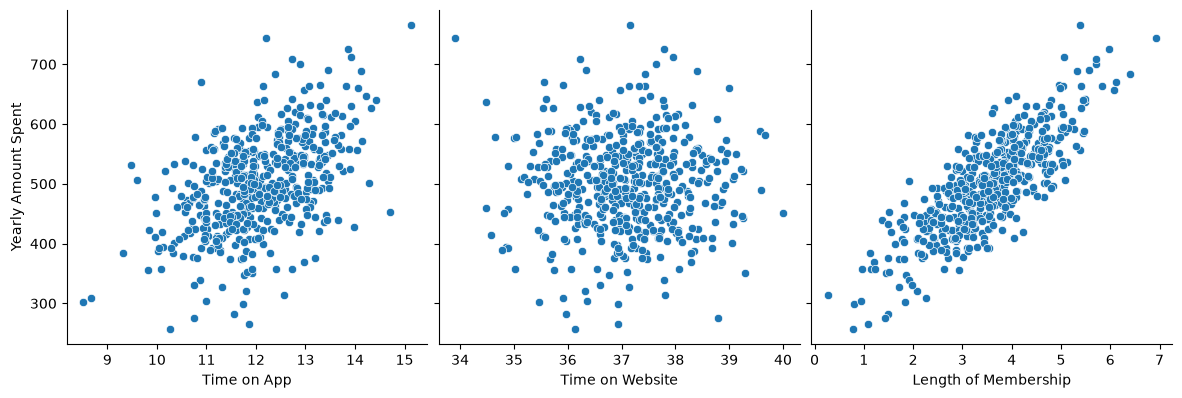

In [6]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

Selanjutnya lihat matriks korelasi antar variabel numerik dengan *heatmap*. Semakin tinggi nilainya, semakin tinggi korelasinya.

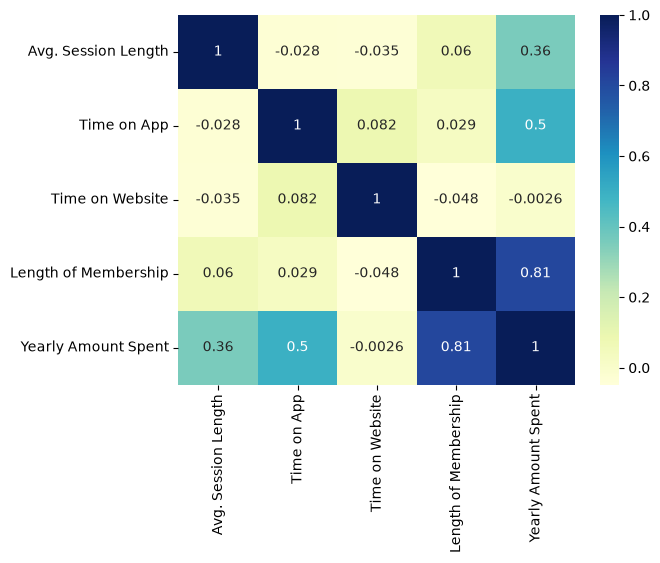

In [7]:
# visualisasi korelasi dengan heatmap
# numeric_only=True agar kolom kategorikal (Email, Address, Avatar) diabaikan (pandas >= 2.0)
sns.heatmap(data.corr(numeric_only=True), cmap='YlGnBu', annot=True)
plt.show()

### Langkah 5 - Regresi Linier
Berdasarkan heatmap, `Length of Membership` memiliki korelasi paling tinggi dengan `Yearly Amount Spent`. Kita jadikan ia variabel bebas X dan target sebagai y.

In [8]:
# Membuat variabel bebas X dan Y
X = data['Length of Membership']
y = data['Yearly Amount Spent']

X.head()

0    4.082621
1    2.664034
2    4.104543
3    3.120179
4    4.446308
Name: Length of Membership, dtype: float64

Bagi data menjadi data latih (70%) dan data uji (30%).

In [9]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

print('Jumlah data latih:', len(X_train))
print('Jumlah data uji  :', len(X_test))

Jumlah data latih: 350
Jumlah data uji  : 150


Latih model regresi linier dengan **StatsModels** (`OLS`). Tambahkan konstanta (intercept) terlebih dahulu.

In [10]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

print('Intercept (beta_0):', lr.params['const'])
print('Slope     (beta_1):', lr.params['Length of Membership'])

Intercept (beta_0): 265.2482985254948
Slope     (beta_1): 66.3015219854631


Tampilkan ringkasan statistik model (koefisien, R², uji t, dsb.).

In [11]:
# analisis statistika dari garis regresi
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Tue, 27 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         19:04:56   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  265.2483      9.120     29.083      0.000     247.311     283.186
Length of Membership    66.3015      2.501     26.512      0.000      61.383      71.220
==============================================================================
Omnibus:                        1.643   Durbin-Watson:                   1.929
Prob(Omnibus):                  0.440   Jarque-Bera (JB):                1.471
Skew:                          -0.013   Prob(JB):                        0.479
Kurtosis:                       2.683   Cond. No.                         14.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

> **Catatan:** modul menuliskan garis `265.2483 + 66.3015*X_train` secara *hardcode*. Nilai tersebut sama dengan parameter hasil fitting; di sini garis diambil langsung dari `lr.params` agar selalu konsisten dengan model.

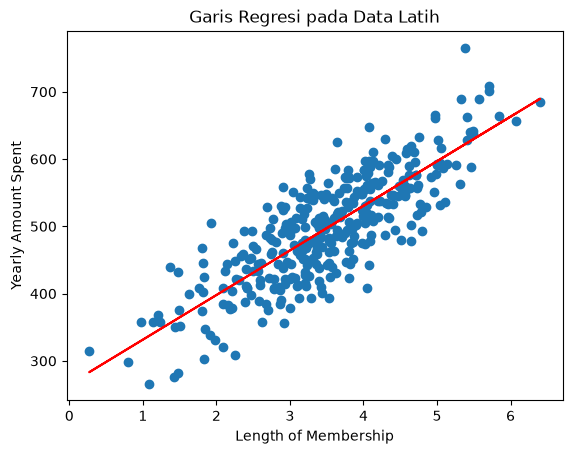

In [12]:
# visualisasi garis regresi
intercept = lr.params['const']
slope = lr.params['Length of Membership']

plt.scatter(X_train, y_train)
plt.plot(X_train, intercept + slope * X_train, 'r')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Garis Regresi pada Data Latih')
plt.show()

### Langkah 6 - Analisis Residual
Prediksi nilai pada data latih lalu hitung residual (selisih nilai aktual dan prediksi).

In [13]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)
res.head()

153   -11.119759
84    -23.238076
310    -8.632781
494    61.834396
126   -20.654448
dtype: float64

Visualisasikan residual dalam bentuk histogram (untuk melihat apakah mendekati distribusi normal) dan scatter plot.

> **Penyesuaian:** `sns.distplot` sudah *deprecated*; diganti `sns.histplot(..., kde=True)`.

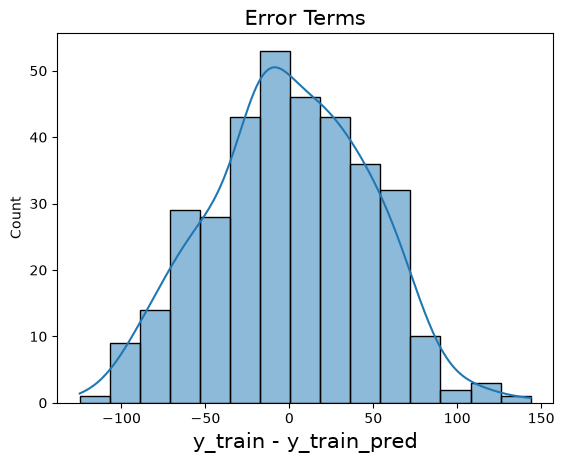

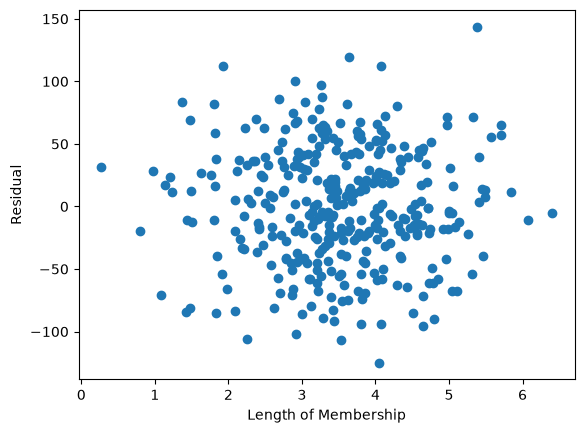

In [14]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.xlabel('Length of Membership')
plt.ylabel('Residual')
plt.show()

### Langkah 7 - Prediksi pada Data Uji dan Evaluasi Model
Prediksi data uji, lalu hitung R-squared.

In [15]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# cetak 5 data terprediksi teratas
y_test_pred.head()

69     500.794385
29     579.688406
471    533.188991
344    446.066436
54     455.838449
dtype: float64

In [16]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
print('R-squared:', r_squared)

R-squared: 0.611948913768747


### Langkah 8 - Visualisasi Hasil
Bandingkan data uji sebenarnya dengan hasil prediksi.

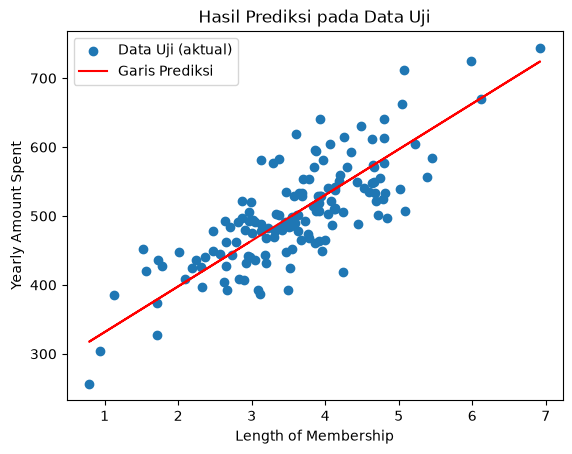

In [17]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test, label='Data Uji (aktual)')
plt.plot(X_test, y_test_pred, 'r', label='Garis Prediksi')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Hasil Prediksi pada Data Uji')
plt.legend()
plt.show()

### Kesimpulan

* Model **Simple Linear Regression** dengan satu fitur `Length of Membership` sudah cukup baik menjelaskan `Yearly Amount Spent`: **R² ≈ 0,67** pada data latih dan **R² ≈ 0,61** pada data uji, artinya sekitar 61% variasi belanja tahunan dapat dijelaskan oleh lama keanggotaan.
* Residual menyebar di sekitar nol, menandakan asumsi linearitas cukup wajar untuk fitur ini.
* Ke depan, **Multiple Linear Regression** (memakai beberapa fitur sekaligus) akan memberi prediksi yang lebih baik — hal ini dikerjakan pada Tugas Praktikum.